<a href="https://colab.research.google.com/github/mirandalohc-sys/comp8240-sbert-replication/blob/main/Copy_of_sbert_verification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import platform
import torch
import scipy
import datasets
import transformers
import sentence_transformers

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("SciPy:", scipy.__version__)
print("datasets:", datasets.__version__)
print("transformers:", transformers.__version__)
print("sentence-transformers:", sentence_transformers.__version__)

Python: 3.13.16
PyTorch: 2.11.0+cpu
SciPy: 1.16.3
datasets: 4.8.5
transformers: 5.18.0
sentence-transformers: 5.7.0


In [ ]:
import platform
from importlib.metadata import version

print("Python:", platform.python_version())

for package in [
    "torch",
    "scipy",
    "datasets",
    "transformers",
    "sentence-transformers"
]:
    print(f"{package}=={version(package)}")

Python: 3.13.16
torch==2.11.0+cpu
scipy==1.16.3
datasets==4.8.5
transformers==5.18.0
sentence-transformers==5.7.0


In [ ]:
from datasets import load_dataset
from scipy.stats import spearmanr
from sentence_transformers import SentenceTransformer, util

ds = load_dataset(
    "sentence-transformers/stsb",
    split="test"
)

s1 = list(ds["sentence1"])
s2 = list(ds["sentence2"])
gold = list(ds["score"])

print(len(gold), "test pairs loaded")

model = SentenceTransformer(
    "sentence-transformers/bert-base-nli-mean-tokens"
)

e1 = model.encode(
    s1,
    batch_size=32,
    convert_to_tensor=True
)

e2 = model.encode(
    s2,
    batch_size=32,
    convert_to_tensor=True
)

cos = util.cos_sim(e1, e2).diagonal()

res = spearmanr(gold, cos.cpu().numpy())

rho = (
    res.statistic
    if hasattr(res, "statistic")
    else res.correlation
)

print(f"Spearman x100: {rho * 100:.2f}")
print("Published result: 77.03")

README.md:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  471kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  142kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Spearman x100: 76.99
Published result: 77.03


In [ ]:
from datasets import load_dataset

biosses = load_dataset("tabilab/biosses", split="train")
biosses_df = biosses.to_pandas()

print("Dataset: BIOSSES")
print("Source: https://huggingface.co/datasets/tabilab/biosses")
print("Number of pairs:", len(biosses_df))
print("Columns:", biosses_df.columns.tolist())
print("Lowest human score:", biosses_df["score"].min())
print("Highest human score:", biosses_df["score"].max())

print("\nMissing values per column:")
print(biosses_df.isna().sum())

print("\nDuplicate sentence pairs:")
print(biosses_df.duplicated(["sentence1", "sentence2"]).sum())

print("\nFirst three examples:")
display(biosses_df.head(3))

README.md:   0%|          | 0.00/6.75k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.1kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100 [00:00<?, ? examples/s]

Dataset: BIOSSES
Source: https://huggingface.co/datasets/tabilab/biosses
Number of pairs: 100
Columns: ['sentence1', 'sentence2', 'score']
Lowest human score: 0.0
Highest human score: 4.0

Missing values per column:
sentence1    0
sentence2    0
score        0
dtype: int64

Duplicate sentence pairs:
0

First three examples:


,sentence1,sentence2,score
0,"Here, looking for agents that could specifical...","Not surprisingly, GATA2 knockdown in KRAS muta...",2.2
1,MLL-FKBP and MLL-AF9 transformed cells showed ...,Regardless of the mechanism for transcriptiona...,3.2
2,The oncogenic activity of mutant Kras appears ...,Oncogenic KRAS mutations are common in cancer.,2.0


In [ ]:
from scipy.stats import spearmanr
from sentence_transformers import util

# Check for empty sentences, including whitespace-only text.
for column in ["sentence1", "sentence2"]:
    assert biosses_df[column].str.strip().ne("").all(), \
        f"Blank sentence found in {column}"

# Convert each sentence into an embedding.
bio_e1 = model.encode(
    biosses_df["sentence1"].tolist(),
    batch_size=32,
    convert_to_tensor=True,
    show_progress_bar=True
)

bio_e2 = model.encode(
    biosses_df["sentence2"].tolist(),
    batch_size=32,
    convert_to_tensor=True,
    show_progress_bar=True
)

# Compare each sentence with its corresponding partner.
bio_cosine = (
    util.cos_sim(bio_e1, bio_e2)
    .diagonal()
    .cpu()
    .numpy()
)

# Compare the model's ranking with the human ranking.
bio_rho = spearmanr(
    biosses_df["score"].to_numpy(),
    bio_cosine
).statistic

# Keep predictions for later inspection.
biosses_results = biosses_df.copy()
biosses_results["sbert_cosine"] = bio_cosine

print("\nModel: bert-base-nli-mean-tokens")
print("Additional training: none")
print("Evaluated pairs:", len(biosses_results))
print(f"BIOSSES Spearman x100: {bio_rho * 100:.2f}")

display(biosses_results[["score", "sbert_cosine"]].head())

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]


Model: bert-base-nli-mean-tokens
Additional training: none
Evaluated pairs: 100
BIOSSES Spearman x100: 51.99


,score,sbert_cosine
0,2.2,0.670693
1,3.2,0.823034
2,2.0,0.589478
3,2.8,0.786370
4,2.4,0.684121


In [ ]:
import pandas as pd

pilot_rows = [
    (
        "P01", "negation",
        "The clinic is open on Saturday.",
        "The clinic is not open on Saturday."
    ),
    (
        "P02", "negation",
        "The library is not open today.",
        "The library is closed today."
    ),
    (
        "P03", "antonymy",
        "The rent increased this year.",
        "The rent decreased this year."
    ),
    (
        "P04", "antonymy",
        "The suitcase is heavy.",
        "The suitcase is light."
    ),
    (
        "P05", "numbers",
        "The bus arrives at 8:15 am.",
        "The bus arrives at 8:50 am."
    ),
    (
        "P06", "numbers",
        "The walk lasted sixty minutes.",
        "The walk lasted one hour."
    ),
    (
        "P07", "word_overlap",
        "The dog chased the boy.",
        "The boy chased the dog."
    ),
    (
        "P08", "word_overlap",
        "The teacher thanked the student.",
        "The student was thanked by the teacher."
    ),
    (
        "P09", "Australian_English",
        "I will stop at the servo for petrol.",
        "I will stop at the petrol station for fuel."
    ),
    (
        "P10", "Australian_English",
        "She packed her swimmers for the beach.",
        "She packed her swimming costume for the beach."
    )
]

pilot_df = pd.DataFrame(
    pilot_rows,
    columns=["pair_id", "category", "sentence1", "sentence2"]
)

pilot_df["draft_origin"] = "AI-assisted; pending human review"

rating_columns = ["rater_1", "rater_2", "rater_3"]

for column in rating_columns:
    pilot_df[column] = pd.NA

print("Draft pairs:", len(pilot_df))
print("\nPairs per category:")
print(pilot_df["category"].value_counts())

print(
    "\nHuman ratings collected:",
    int(pilot_df[rating_columns].notna().sum().sum())
)

display(pilot_df[["pair_id", "category", "sentence1", "sentence2"]])

Draft pairs: 10

Pairs per category:
category
negation              2
antonymy              2
numbers               2
word_overlap          2
Australian_English    2
Name: count, dtype: int64

Human ratings collected: 0


,pair_id,category,sentence1,sentence2
0,P01,negation,The clinic is open on Saturday.,The clinic is not open on Saturday.
1,P02,negation,The library is not open today.,The library is closed today.
2,P03,antonymy,The rent increased this year.,The rent decreased this year.
3,P04,antonymy,The suitcase is heavy.,The suitcase is light.
4,P05,numbers,The bus arrives at 8:15 am.,The bus arrives at 8:50 am.
5,P06,numbers,The walk lasted sixty minutes.,The walk lasted one hour.
6,P07,word_overlap,The dog chased the boy.,The boy chased the dog.
7,P08,word_overlap,The teacher thanked the student.,The student was thanked by the teacher.
8,P09,Australian_English,I will stop at the servo for petrol.,I will stop at the petrol station for fuel.
9,P10,Australian_English,She packed her swimmers for the beach.,She packed her swimming costume for the beach.


In [ ]:
import zipfile
from google.colab import files

# Check the draft data.
pilot_checked = pilot_df.copy()
required = ["pair_id", "category", "sentence1", "sentence2"]

assert not pilot_checked[required].isna().any().any(), \
    "Missing information found."

for column in required:
    pilot_checked[column] = (
        pilot_checked[column]
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )
    assert pilot_checked[column].ne("").all(), \
        f"Blank text found in {column}."

assert pilot_checked["pair_id"].is_unique, "Repeated pair IDs found."

# Detect repeated pairs, including reversed sentence order.
pair_keys = pilot_checked.apply(
    lambda row: tuple(sorted([
        row["sentence1"].casefold(),
        row["sentence2"].casefold()
    ])),
    axis=1
)
assert not pair_keys.duplicated().any(), "Repeated sentence pairs found."

instructions = """SENTENCE SIMILARITY PILOT

Judge how similar the meanings of the two sentences are.
Use a whole number from 0 to 5:

5: Both sentences express the same complete meaning.
4: The main meaning matches; only minor details differ.
3: Meanings are broadly similar, but important information differs.
2: Some details match, but the overall meanings differ.
1: Only the general topic is shared.
0: The meanings are unrelated.

Judge meaning, not the number of matching words.
A contradiction is not automatically a score of zero.

Work independently. Do not consult another rater, AI, or model scores.
Enter your rating in human_score.
Use comment to flag unclear wording or unfamiliar expressions.
If you cannot judge a pair, leave its score blank and explain why.
Do not change the sentences or pair IDs.
Do not include your name or other identifying information.
"""

zip_name = "sbert_pilot_annotation_pack.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as pack:
    pack.writestr("READ_ME.txt", instructions)

    for rater in range(1, 4):
        sheet = (
            pilot_checked[["pair_id", "sentence1", "sentence2"]]
            .sample(frac=1, random_state=8240 + rater)
            .reset_index(drop=True)
        )
        sheet["human_score"] = ""
        sheet["comment"] = ""

        pack.writestr(
            f"pilot_rater_{rater}.csv",
            sheet.to_csv(index=False).encode("utf-8-sig")
        )

print("Quality checks passed.")
print("Three shuffled rating sheets prepared.")
print("Each sheet contains", len(pilot_checked), "pairs.")
print("Human ratings have not been collected by this cell.")

files.download(zip_name)

Quality checks passed.
Three shuffled rating sheets prepared.
Each sheet contains 10 pairs.
Human ratings have not been collected by this cell.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, bootstrap
from google.colab import files

# Reproducible resampling.
ci_rng = np.random.default_rng(8240)

def correlation_only(human, predicted):
    return spearmanr(human, predicted).statistic

def evaluate_with_ci(dataset_name, human, predicted):
    human = np.asarray(human, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    assert len(human) == len(predicted), "Different numbers of scores."
    assert np.isfinite(human).all(), "Missing or invalid human scores."
    assert np.isfinite(predicted).all(), "Missing or invalid predictions."

    result = bootstrap(
        data=(human, predicted),
        statistic=correlation_only,
        paired=True,
        vectorized=False,
        n_resamples=5000,
        batch=200,
        confidence_level=0.95,
        method="BCa",
        rng=ci_rng
    )

    lower = result.confidence_interval.low * 100
    upper = result.confidence_interval.high * 100
    assert np.isfinite([lower, upper]).all(), "Check bootstrap output."

    return {
        "Dataset": dataset_name,
        "Pairs": len(human),
        "Spearman x100": correlation_only(human, predicted) * 100,
        "95% CI lower": lower,
        "95% CI upper": upper
    }

# Reuse your actual predictions; no additional model training.
summary_df = pd.DataFrame([
    evaluate_with_ci(
        "STS-B test",
        gold,
        cos.detach().cpu().numpy()
    ),
    evaluate_with_ci(
        "BIOSSES",
        biosses_results["score"].to_numpy(),
        biosses_results["sbert_cosine"].to_numpy()
    )
])

display(summary_df.round(2))

print("Method: 95% BCa paired bootstrap")
print("Resamples: 5,000 per dataset; random seed: 8240")
print("Checkpoint: bert-base-nli-mean-tokens")
print("Additional training: none")

filename = "sbert_results_with_confidence_intervals.csv"
summary_df.to_csv(filename, index=False)
files.download(filename)

,Dataset,Pairs,Spearman x100,95% CI lower,95% CI upper
0,STS-B test,1379,76.99,74.49,79.23
1,BIOSSES,100,51.99,34.59,66.04


Method: 95% BCa paired bootstrap
Resamples: 5,000 per dataset; random seed: 8240
Checkpoint: bert-base-nli-mean-tokens
Additional training: none


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next actions — planned work

### 1. Collect ratings
Ask three people to independently rate each pilot sentence pair from 0–5.

### 2. Assess agreement
Use ordinal Krippendorff’s alpha to check how consistently the three people rate the pairs.

### 3. Inspect errors
Compare SBERT’s predictions with the human ratings and investigate disagreements.

**Current progress:** Ten draft pairs and three shuffled rating forms are prepared. Human ratings are pending.

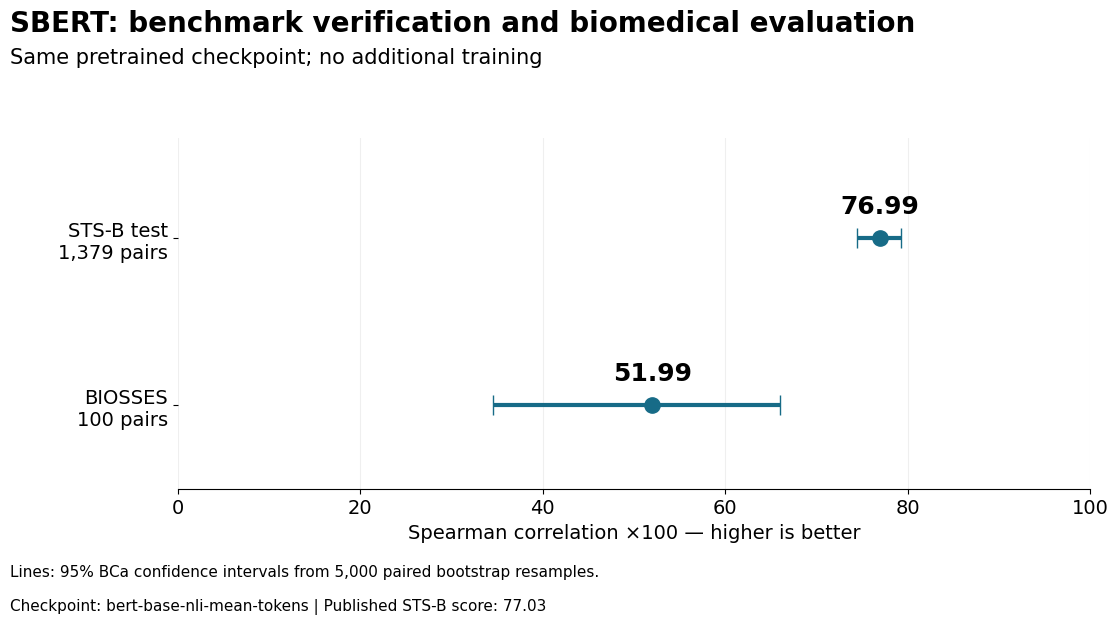

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import zipfile
from google.colab import files

# Use the results you have already calculated.
plot_df = (
    summary_df.set_index("Dataset")
    .loc[["STS-B test", "BIOSSES"]]
    .reset_index()
)

scores = plot_df["Spearman x100"].to_numpy()
lower = plot_df["95% CI lower"].to_numpy()
upper = plot_df["95% CI upper"].to_numpy()
positions = np.array([1, 0])

fig, ax = plt.subplots(figsize=(12, 6.75))
fig.subplots_adjust(left=0.19, right=0.95, top=0.77, bottom=0.25)

ax.errorbar(
    scores,
    positions,
    xerr=np.vstack([scores - lower, upper - scores]),
    fmt="o",
    markersize=11,
    capsize=7,
    linewidth=3,
    color="#176B87"
)

for score, position in zip(scores, positions):
    ax.annotate(
        f"{score:.2f}",
        (score, position),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=18,
        fontweight="bold"
    )

labels = [
    f"{row['Dataset']}\n{int(row['Pairs']):,} pairs"
    for _, row in plot_df.iterrows()
]

ax.set_yticks(positions, labels=labels)
ax.set_xlim(0, 100)
ax.set_ylim(-0.5, 1.6)
ax.set_xlabel("Spearman correlation ×100 — higher is better", fontsize=14)
ax.tick_params(axis="both", labelsize=14)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

fig.suptitle(
    "SBERT: benchmark verification and biomedical evaluation",
    x=0.05, y=0.96, ha="left", fontsize=20, fontweight="bold"
)
fig.text(
    0.05, 0.88,
    "Same pretrained checkpoint; no additional training",
    fontsize=15
)
fig.text(
    0.05, 0.12,
    "Lines: 95% BCa confidence intervals from 5,000 paired bootstrap resamples.",
    fontsize=11
)
fig.text(
    0.05, 0.07,
    "Checkpoint: bert-base-nli-mean-tokens | Published STS-B score: 77.03",
    fontsize=11
)

fig.savefig("sbert_results.png", dpi=300, facecolor="white")
fig.savefig("sbert_results.pdf", facecolor="white")
plt.show()

summary_df.to_csv("sbert_results_table.csv", index=False)

with zipfile.ZipFile(
    "sbert_presentation_results.zip", "w", zipfile.ZIP_DEFLATED
) as pack:
    for filename in [
        "sbert_results.png",
        "sbert_results.pdf",
        "sbert_results_table.csv"
    ]:
        pack.write(filename)

files.download("sbert_presentation_results.zip")

In [ ]:
import pandas as pd
from sentence_transformers import util
from scipy.stats import spearmanr
from IPython.display import display, Markdown

# Take two actual pairs from your existing STS-B test dataset.
demo_df = ds.select([0, 1]).to_pandas()[
    ["sentence1", "sentence2", "score"]
].copy()

# Run the encoder on these two pairs.
demo_e1 = model.encode(
    demo_df["sentence1"].tolist(),
    convert_to_tensor=True,
    show_progress_bar=False
)

demo_e2 = model.encode(
    demo_df["sentence2"].tolist(),
    convert_to_tensor=True,
    show_progress_bar=False
)

demo_df["Model cosine"] = (
    util.cos_sim(demo_e1, demo_e2)
    .diagonal()
    .detach()
    .cpu()
    .numpy()
)

demo_df = demo_df.rename(columns={
    "sentence1": "Sentence 1",
    "sentence2": "Sentence 2",
    "score": "Human score (dataset scale)"
})

display(
    demo_df.style
    .hide(axis="index")
    .format({
        "Human score (dataset scale)": "{:.3f}",
        "Model cosine": "{:.3f}"
    })
    .set_properties(**{
        "white-space": "normal",
        "max-width": "320px",
        "font-size": "18px"
    })
)

# Recalculate the full-test correlation from existing predictions.
demo_full_rho = spearmanr(
    gold,
    cos.detach().cpu().numpy()
).statistic

display(Markdown(
    f"**Full STS-B test set: {len(gold):,} pairs**  \n"
    f"**Spearman ×100: {demo_full_rho * 100:.2f}**"
))

Sentence 1,Sentence 2,Human score (dataset scale),Model cosine
A girl is styling her hair.,A girl is brushing her hair.,0.500,0.915
A group of men play soccer on the beach.,A group of boys are playing soccer on the beach.,0.720,0.974


**Full STS-B test set: 1,379 pairs**  
**Spearman ×100: 76.99**

In [ ]:
import pandas as pd
from IPython.display import display

# Check required fields only.
# Pending human-rating fields are allowed to be empty.
required_cols = [
    "pair_id", "category", "sentence1", "sentence2"
]

pilot_text = (
    pilot_df[required_cols]
    .fillna("")
    .astype(str)
    .apply(lambda column: column.str.strip())
)

# Treat A–B and B–A as the same pair.
# Ignore capitalisation and surrounding spaces.
pair_keys = pilot_text.apply(
    lambda row: tuple(sorted([
        row["sentence1"].casefold(),
        row["sentence2"].casefold()
    ])),
    axis=1
)

rating_cols = ["rater_1", "rater_2", "rater_3"]
numeric_ratings = pilot_df[rating_cols].apply(
    pd.to_numeric, errors="coerce"
)

pilot_checks = pd.DataFrame({
    "Check": [
        "Draft pairs",
        "Blank required fields",
        "Duplicate pair IDs",
        "Repeated pairs, including reversed pairs",
        "Human ratings collected"
    ],
    "Result": [
        len(pilot_df),
        int(pilot_text.eq("").sum().sum()),
        int(pilot_text["pair_id"].str.casefold().duplicated().sum()),
        int(pair_keys.duplicated().sum()),
        int(numeric_ratings.notna().sum().sum())
    ]
})

display(
    pilot_checks.style
    .hide(axis="index")
    .set_properties(**{"font-size": "20px"})
)

Check,Result
Draft pairs,10
Blank required fields,0
Duplicate pair IDs,0
"Repeated pairs, including reversed pairs",0
Human ratings collected,0


## Pilot rating guide — draft

Rate similarity of meaning, not just shared words.
Choose one whole-number score from 0 to 5.

| Score | Meaning |
|---|---|
| 0 | Completely unrelated meanings |
| 1 | Same broad topic, but very little shared meaning |
| 2 | Some shared meaning, with major differences |
| 3 | Mostly similar meaning, with an important difference |
| 4 | Nearly equivalent, with only minor differences |
| 5 | Equivalent meaning |

Work independently without viewing model predictions.
Add a comment if a pair is unclear.
